# Does Development Cross Borders?
## A network analysis of human development across the land borders of Europe and Asia

**Course project — Network analysis** · Tools: Python (`pandas`, `networkx`, `scikit-learn`, `matplotlib`)

---

### 1. Research question

Economists and geographers often claim that prosperity is *spatially contagious*: trade, labour mobility, infrastructure, institutions and even conflict spill over borders, so neighbouring countries should end up with similar living standards. If that is true, **the land-border network itself should carry information about development** — a purely structural object (who touches whom) should line up with a purely socio-economic one (how long people live, how long they study, how much they earn).

**Main question:** *Do countries that share a border also share a level of human development — and where does this rule break down?*

Sub-questions that structure the analysis:

1. **Centrality (RQ1).** Which countries are structurally most important in the Eurasian border network (hubs, bridges), and is structural importance related to development?
2. **Communities (RQ2).** Which regional blocs does the border network split into on its own, without any attribute information?
3. **Attribute clusters (RQ3).** What natural development groups exist when we cluster countries only by their UNDP indicators, and what do the cluster *centroids* look like?
4. **Linking the layers (RQ4).** Do border communities coincide with development clusters? Are neighbours more similar than chance (assortativity)? Which borders are the sharpest **"development cliffs"**?

### 2. Data

**Nodes = 78 countries of Europe and Asia.** Inclusion rule: UN member or observer states in the UN-M49 regions *Europe* and *Asia* that (a) appear in the UNDP *Human Development Report 2025*, Table 1 (data year 2023), and (b) have at least one land border or permanent fixed link to another included country.

*Excluded, with reason:* island states without a land border or fixed link (Iceland, Malta, Cyprus, Japan, Philippines, Sri Lanka, Maldives); micro-states (Andorra, Liechtenstein, Monaco, San Marino, Vatican — tiny enclaves with degree 1–2 that would distort centrality); North Korea (no HDI, GNI or schooling data), which in turn leaves South Korea without a land neighbour; territories not listed as sovereign states in Table 1 (Hong Kong, Kosovo, Taiwan). Egypt and Papua New Guinea are outside the two regions, so their borders with Israel/Palestine and Indonesia are not included.

**Links = 160 undirected edges.** An edge means the two countries share a **land border (156 edges)** or a **permanent road/rail fixed link (4 edges:** Channel Tunnel UK–France, Øresund Bridge Denmark–Sweden, King Fahd Causeway Bahrain–Saudi Arabia, Johor–Singapore Causeway). Fixed links are included because they function exactly like land borders for trade and travel; without them the UK/Ireland, Bahrain and Singapore would be cut off from the network.

**Node attributes (two types)**

| Attribute | Type | Source | Meaning |
|---|---|---|---|
| `life_expectancy` | numeric (years) | UNDP HDR 2025, Table 1 | Life expectancy at birth, 2023 |
| `expected_schooling` | numeric (years) | UNDP HDR 2025, Table 1 | Years of school a child entering school can expect |
| `mean_schooling` | numeric (years) | UNDP HDR 2025, Table 1 | Average years of schooling of adults 25+ |
| `gni_pc_ppp` | numeric (2021 PPP $) | UNDP HDR 2025, Table 1 | Gross national income per capita |
| `hdi` | numeric (0–1) | UNDP HDR 2025, Table 1 | Human Development Index (composite of the four above) |
| `hdi_group` | categorical | derived from UNDP cut-offs | Very high ≥ 0.800, High ≥ 0.700, Medium ≥ 0.550, Low |
| `subregion`, `continent` | categorical | UN-M49 | Geographic region |
| `landlocked`, `eu_member`, `former_ussr` | binary | public record | Political / geographic context |
| `plot_lat`, `plot_lon` | numeric | approximate capital or geographic centre | **used only to draw maps**, not in any analysis |

The two CSV files are produced by `build_dataset.py` (included with the project). It contains the UNDP values transcribed from Table 1 and the hand-coded border list; an automatic check confirms every border is listed symmetrically on both sides.

The four HDI *components* are the clustering features. The HDI itself is a deterministic function of them, so it is used only for colouring and for the assortativity tests, never as an extra clustering feature (that would double-count).

In [1]:
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt, matplotlib as mpl
from networkx.algorithms import community as nxc
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.manifold import MDS, TSNE
from scipy.cluster.hierarchy import linkage, dendrogram
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

nodes = pd.read_csv("nodes_eurasia_hdi.csv")
edges = pd.read_csv("edges_eurasia_borders.csv")
print(f"{len(nodes)} nodes, {len(edges)} edges")
print(edges.edge_type.value_counts().to_string())
display(nodes.head(8))

78 nodes, 160 edges
edge_type
land border    156
fixed link       4


,country,iso3,subregion,continent,landlocked,eu_member,former_ussr,plot_lat,plot_lon,hdi,life_expectancy,expected_schooling,mean_schooling,gni_pc_ppp,hdi_group
0,Albania,ALB,Southern Europe,Europe,0,0,0,41.00,20.00,0.810,79.6,14.5,10.2,17627,Very high
1,Austria,AUT,Western Europe,Europe,1,1,0,47.60,14.60,0.930,82.0,16.3,12.4,63479,Very high
2,Belarus,BLR,Eastern Europe,Europe,1,0,1,53.90,27.57,0.824,74.4,13.7,12.3,26725,Very high
3,Belgium,BEL,Western Europe,Europe,0,1,0,50.85,4.35,0.951,82.1,19.0,12.7,63582,Very high
4,Bosnia and Herzegovina,BIH,Southern Europe,Europe,0,0,0,44.20,17.80,0.804,77.9,13.2,11.0,19827,Very high
5,Bulgaria,BGR,Eastern Europe,Europe,0,1,0,42.70,23.32,0.845,75.6,15.3,11.5,32175,Very high
6,Croatia,HRV,Southern Europe,Europe,0,1,0,45.30,16.30,0.889,78.6,16.3,12.1,41380,Very high
7,Czechia,CZE,Eastern Europe,Europe,1,1,0,49.80,15.30,0.915,79.8,16.8,13.0,45889,Very high


In [2]:
# Descriptive statistics of the numeric attributes
num_cols = ["hdi", "life_expectancy", "expected_schooling", "mean_schooling", "gni_pc_ppp"]
display(nodes[num_cols].describe().round(2))
display(pd.crosstab(nodes.subregion, nodes.hdi_group)[["Very high", "High", "Medium", "Low"]])

,hdi,life_expectancy,expected_schooling,mean_schooling,gni_pc_ppp
count,78.00,78.00,78.00,78.00,78.00
mean,0.82,76.78,14.78,10.61,35683.74
std,0.12,4.95,2.75,2.68,27222.16
min,0.47,65.20,7.40,2.50,1018.00
25%,0.75,73.05,13.20,9.33,13735.75
50%,0.84,77.15,14.85,11.40,32364.00
75%,0.91,81.55,16.70,12.68,51866.50
max,0.97,84.00,20.80,14.30,112710.00


hdi_group,Very high,High,Medium,Low
subregion,,,,
Central Asia,1,3,1,0
Eastern Asia,0,2,0,0
Eastern Europe,8,2,0,0
Northern Europe,9,0,0,0
South-eastern Asia,3,3,4,0
Southern Asia,0,1,4,2
Southern Europe,11,0,0,0
Western Asia,10,3,3,1
Western Europe,7,0,0,0


### 3. Building the network

Nodes carry all attributes; edges carry their type (land border / fixed link). The graph is undirected and unweighted: a border either exists or it does not.

In [3]:
G = nx.Graph()
for r in nodes.to_dict("records"):
    G.add_node(r["iso3"], **r)
for r in edges.to_dict("records"):
    G.add_edge(r["source"], r["target"], edge_type=r["edge_type"])
name = nx.get_node_attributes(G, "country")

summary = {
    "nodes": G.number_of_nodes(), "edges": G.number_of_edges(),
    "connected": nx.is_connected(G), "density": round(nx.density(G), 4),
    "average degree": round(2 * G.number_of_edges() / G.number_of_nodes(), 2),
    "diameter (hops)": nx.diameter(G),
    "average shortest path": round(nx.average_shortest_path_length(G), 2),
    "average clustering": round(nx.average_clustering(G), 3),
    "articulation points": ", ".join(name[n] for n in nx.articulation_points(G)),
}
display(pd.Series(summary, name="value"))

,value
nodes,78
edges,160
connected,True
density,0.0533
average degree,4.1
diameter (hops),11
average shortest path,4.47
average clustering,0.495
articulation points,"Spain, France, United Kingdom, Malaysia, Indonesia, Thailand, Saudi Arabia"


The network is **connected** (one can travel overland or by fixed link from Lisbon to Dili), very **sparse** (density 0.05, about 4 neighbours per country) and **long** (diameter 11; the longest shortest paths run from the Atlantic fringe, e.g. Portugal, to Timor-Leste). The high clustering (≈ 0.50) is typical of planar, geographic networks: your neighbours tend to be each other's neighbours. Articulation points are countries whose removal disconnects the graph — e.g. **Spain** (only gateway to Portugal), **France** (only gateway to the UK and Ireland), **Saudi Arabia** (only gateway to Qatar, Bahrain, UAE, Oman and Yemen) and **Thailand → Malaysia → Indonesia** (the chain to maritime South-East Asia).

The helper below draws the network on approximate geographic coordinates, so communities and clusters can be read like a map.

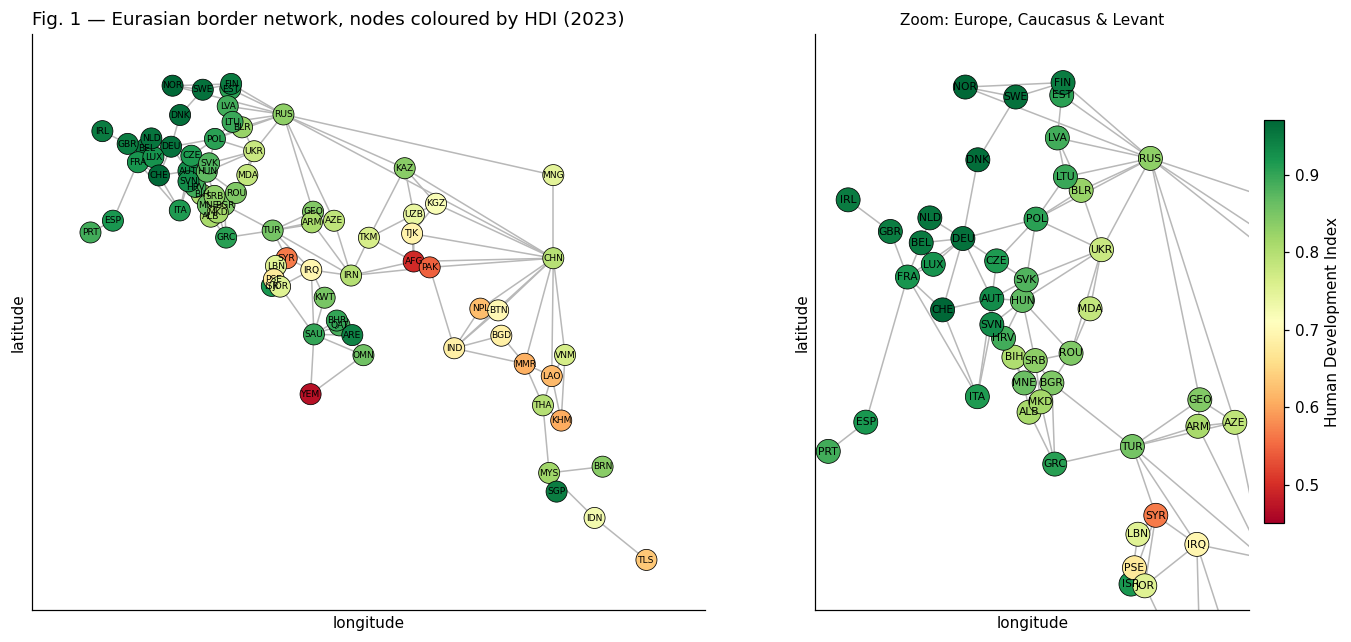

In [4]:
pos = {n: (G.nodes[n]["plot_lon"], G.nodes[n]["plot_lat"]) for n in G}
EUROPE_BOX = (-11, 52, 29.5, 63)   # lon_min, lon_max, lat_min, lat_max

def draw_map(node_color, title, sizes=None, cmap=None, vmin=None, vmax=None,
             legend=None, cbar_label=None, edge_color=None, edge_width=None):
    fig, axes = plt.subplots(1, 2, figsize=(17, 6.8), gridspec_kw={"width_ratios": [1.55, 1]})
    for ax, zoom in zip(axes, [False, True]):
        nl = list(G) if not zoom else [n for n in G if EUROPE_BOX[0] <= pos[n][0] <= EUROPE_BOX[1]
                                       and EUROPE_BOX[2] <= pos[n][1] <= EUROPE_BOX[3]]
        el = [e for e in G.edges() if not zoom or (e[0] in nl or e[1] in nl)]
        ec = "#b8b8b8" if edge_color is None else [edge_color[e] for e in el]
        ew = 1.0 if edge_width is None else [edge_width[e] for e in el]
        nx.draw_networkx_edges(G, pos, edgelist=el, ax=ax, edge_color=ec, width=ew)
        sc = nx.draw_networkx_nodes(G, pos, nodelist=nl, ax=ax,
                                    node_color=[node_color[n] for n in nl],
                                    node_size=[(sizes[n] if sizes else 190) * (1.3 if zoom else 1) for n in nl],
                                    cmap=cmap, vmin=vmin, vmax=vmax, edgecolors="black", linewidths=0.5)
        nx.draw_networkx_labels(G, pos, labels={n: n for n in nl}, ax=ax, font_size=6 if not zoom else 7)
        if zoom:
            ax.set_xlim(EUROPE_BOX[0], EUROPE_BOX[1]); ax.set_ylim(EUROPE_BOX[2], EUROPE_BOX[3])
            ax.set_title("Zoom: Europe, Caucasus & Levant", fontsize=10)
        else:
            ax.set_title(title, fontsize=12, loc="left")
        ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.tick_params(labelsize=7)
    if cmap is not None:
        cb = fig.colorbar(sc, ax=axes, shrink=0.7, pad=0.01); cb.set_label(cbar_label)
    if legend:
        axes[0].legend(handles=legend, loc="lower left", fontsize=8, frameon=True)
    plt.show()

draw_map({n: G.nodes[n]["hdi"] for n in G}, "Fig. 1 — Eurasian border network, nodes coloured by HDI (2023)",
         cmap=plt.cm.RdYlGn, vmin=0.45, vmax=0.97, cbar_label="Human Development Index")

Fig. 1 already hints at the answer: colours change *gradually* across most of Europe and East Asia, but there are abrupt jumps in the Middle East (green Gulf states next to red Yemen; Israel next to Syria and Palestine) and around Afghanistan and Pakistan. The rest of the notebook tests this impression formally.

---
### 4. Node centrality (RQ1)

Four centrality measures, each answering a different question:

* **Degree** — how many neighbours a country has (exposure to many markets, many potential conflicts).
* **Betweenness** — how often a country lies on the shortest overland path between two others (**transit / bridge role**).
* **Closeness** — how few border crossings it takes, on average, to reach everyone else (**geographic centrality**).
* **Eigenvector** — whether a country is connected to other well-connected countries (**embeddedness in the dense core**).

In [5]:
cent = pd.DataFrame({
    "degree": dict(G.degree()),
    "betweenness": nx.betweenness_centrality(G),
    "closeness": nx.closeness_centrality(G),
    "eigenvector": nx.eigenvector_centrality(G, max_iter=2000),
})
cent.insert(0, "country", cent.index.map(name))
cent["hdi"] = cent.index.map(nx.get_node_attributes(G, "hdi"))
for m in ["degree", "betweenness", "closeness", "eigenvector"]:
    nx.set_node_attributes(G, cent[m].to_dict(), m)

top = {m: cent.sort_values(m, ascending=False).head(10).apply(lambda r: f"{r.country} ({r[m]:.3g})", axis=1).values
       for m in ["degree", "betweenness", "closeness", "eigenvector"]}
display(pd.DataFrame(top, index=range(1, 11)))

,degree,betweenness,closeness,eigenvector
1,China (13),Russia (0.463),Russia (0.348),Russia (0.387)
2,Russia (13),China (0.323),China (0.313),China (0.337)
3,Germany (9),Türkiye (0.224),Azerbaijan (0.308),Poland (0.24)
4,Saudi Arabia (8),Poland (0.216),Georgia (0.303),Ukraine (0.223)
5,Türkiye (8),Germany (0.203),Poland (0.303),Belarus (0.204)
6,Austria (7),Iraq (0.199),Ukraine (0.302),Kazakhstan (0.194)
7,Hungary (7),Iran (0.159),Kazakhstan (0.294),Afghanistan (0.179)
8,Poland (7),Saudi Arabia (0.126),Iran (0.293),Lithuania (0.171)
9,Iran (7),Thailand (0.123),Türkiye (0.288),Azerbaijan (0.163)
10,Ukraine (7),Ukraine (0.114),Belarus (0.287),Iran (0.161)


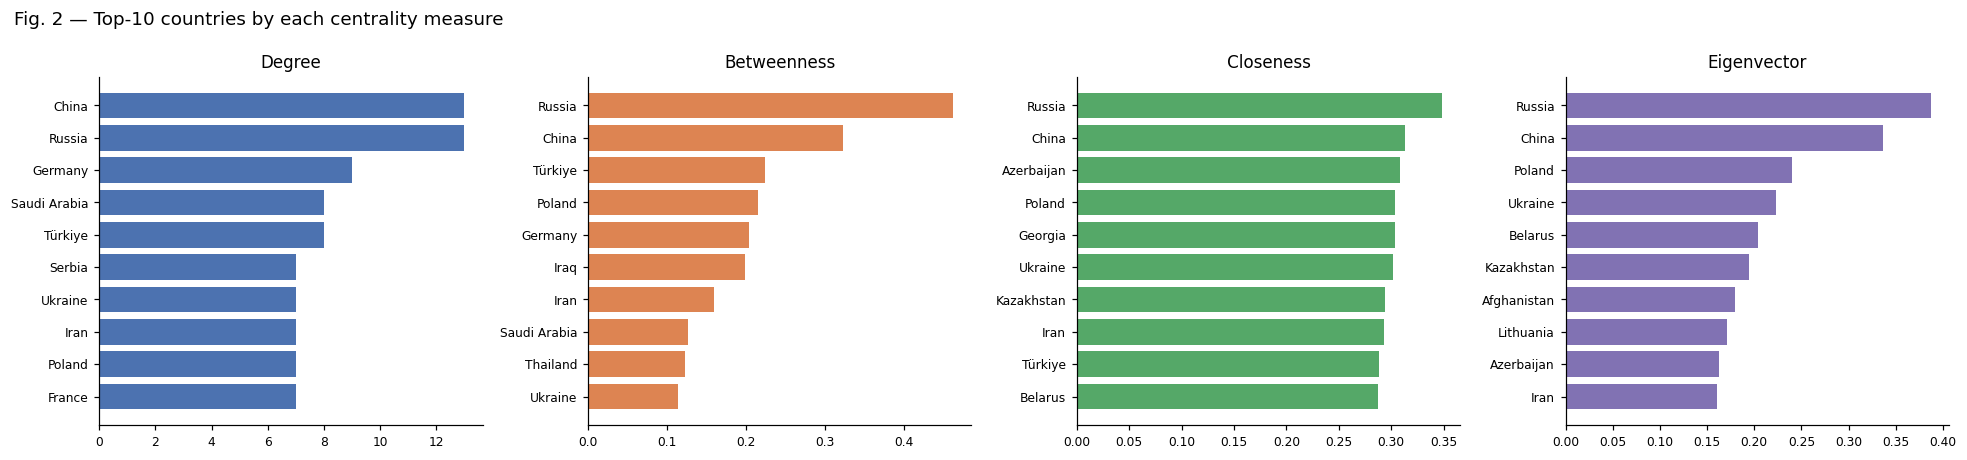

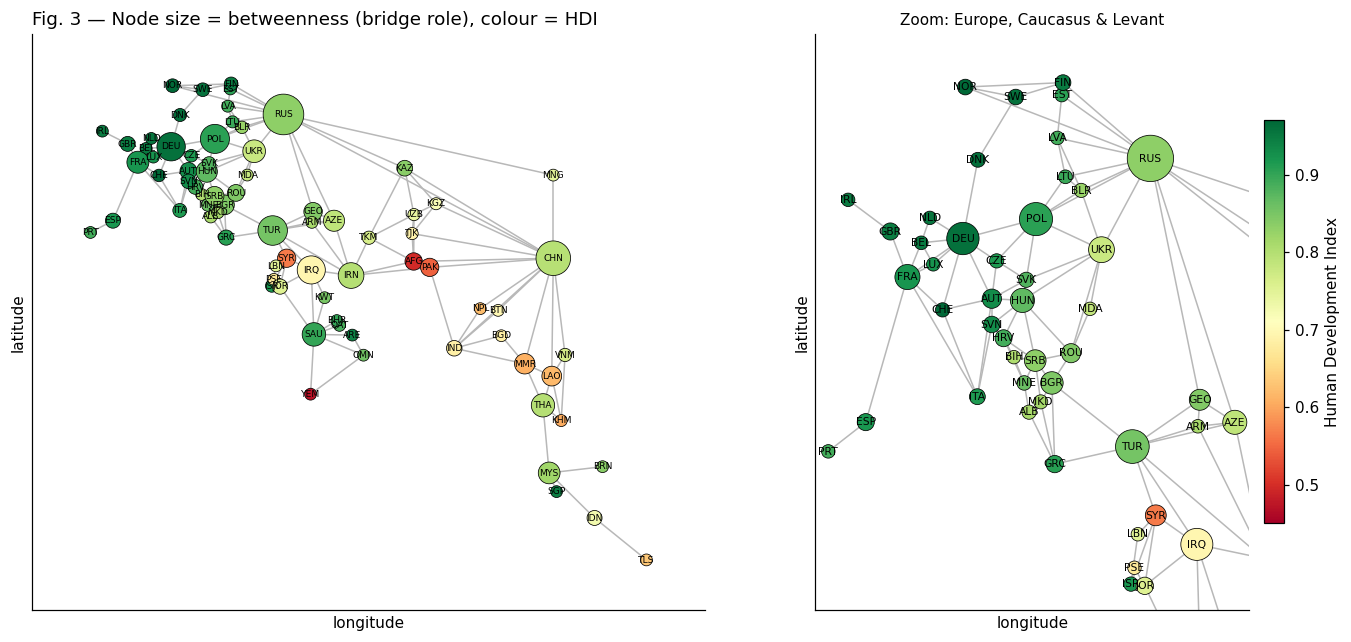

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, m, col in zip(axes, ["degree", "betweenness", "closeness", "eigenvector"],
                      ["#4c72b0", "#dd8452", "#55a868", "#8172b3"]):
    t = cent.sort_values(m).tail(10)
    ax.barh(t.country, t[m], color=col); ax.set_title(m.capitalize(), fontsize=11); ax.tick_params(labelsize=8)
fig.suptitle("Fig. 2 — Top-10 countries by each centrality measure", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

bet = cent.betweenness
draw_map({n: G.nodes[n]["hdi"] for n in G}, "Fig. 3 — Node size = betweenness (bridge role), colour = HDI",
         sizes={n: 60 + 1400 * bet[n] for n in G}, cmap=plt.cm.RdYlGn, vmin=0.45, vmax=0.97,
         cbar_label="Human Development Index")

In [7]:
# Is structural importance related to development?  (Spearman rank correlation, n = 78)
from scipy.stats import spearmanr
rows = []
for m in ["degree", "betweenness", "closeness", "eigenvector"]:
    rho, p = spearmanr(cent[m], cent.hdi)
    rows.append({"measure": m, "Spearman rho with HDI": round(rho, 3), "p-value": round(p, 3)})
display(pd.DataFrame(rows).set_index("measure"))

# Most critical individual borders: edge betweenness
eb = nx.edge_betweenness_centrality(G)
display(pd.DataFrame([{"border": f"{name[a]} – {name[b]}", "edge betweenness": round(v, 3)}
                      for (a, b), v in sorted(eb.items(), key=lambda x: -x[1])[:8]]))

,Spearman rho with HDI,p-value
measure,,
degree,-0.088,0.441
betweenness,-0.021,0.857
closeness,-0.159,0.165
eigenvector,-0.179,0.116


,border,edge betweenness
0,Russia – China,0.227
1,Poland – Russia,0.201
2,Germany – Poland,0.181
3,Iraq – Saudi Arabia,0.134
4,Thailand – Malaysia,0.122
5,Iran – Iraq,0.114
6,Russia – Ukraine,0.107
7,Russia – Azerbaijan,0.106


**Interpretation (RQ1).**

* **Russia and China dominate every measure.** They tie on degree (13 neighbours each) and rank 1–2 on betweenness, closeness and eigenvector. Russia alone lies on **46 %** of all shortest paths. Structurally they are the hinges of the continent: Russia links the European core to Central Asia, the Caucasus and East Asia; China links Central, South and South-East Asia.
* Closeness ranks the **South Caucasus** (Azerbaijan, Georgia) right after Russia and China: the isthmus between the Black and Caspian Seas sits in the middle of the network, a few crossings from both ends of the continent.
* **Türkiye** (betweenness 3rd) is the bridge between Europe, the Caucasus and the Middle East. **Poland and Germany** form the European corridor between the Western European core and the post-Soviet East. **Iraq and Iran** connect the Arabian Peninsula to the rest of Asia.
* The single most critical border is **Russia–China**, followed by **Poland–Russia** and **Germany–Poland**. These three edges form the backbone of the Lisbon-to-Beijing overland corridor.
* **Centrality is unrelated to development.** All four Spearman correlations with HDI are close to zero or slightly negative, and none is significant. The most developed countries (Norway, Switzerland, Denmark, the Benelux) sit at the **periphery**. Being a structural hub is a matter of size and location, not prosperity.

Centrality therefore tells us *who connects the system*, but not *who is developed*. To see whether development follows the network we need the next layers.

---
### 5. Community detection (RQ2)

We use the **Louvain** algorithm (modularity maximisation, `networkx.louvain_communities`). Louvain is randomised, so it is run with 100 seeds and the partition with the highest modularity is kept. Robustness is checked two ways: against a second algorithm (greedy modularity, Clauset–Newman–Moore), and by measuring how much the 100 Louvain runs agree with the chosen partition.

In [8]:
runs = [nxc.louvain_communities(G, seed=s) for s in range(100)]
mods = [nxc.modularity(G, c) for c in runs]
best = runs[int(np.argmax(mods))]
print(f"Louvain modularity: best = {max(mods):.3f}, median over 100 runs = {np.median(mods):.3f}, "
      f"#communities in best = {len(best)}")

def labels_of(part):
    lab = {n: i for i, c in enumerate(part) for n in c}
    return [lab[n] for n in G]

ari_runs = [adjusted_rand_score(labels_of(best), labels_of(r)) for r in runs]
print(f"Agreement of the 100 runs with the best partition: mean ARI = {np.mean(ari_runs):.2f}")
greedy = nxc.greedy_modularity_communities(G)
print(f"Greedy modularity: {len(greedy)} communities, Q = {nxc.modularity(G, greedy):.3f}, "
      f"ARI vs Louvain = {adjusted_rand_score(labels_of(best), labels_of(greedy)):.2f}")

Louvain modularity: best = 0.666, median over 100 runs = 0.660, #communities in best = 7
Agreement of the 100 runs with the best partition: mean ARI = 0.86
Greedy modularity: 7 communities, Q = 0.653, ARI vs Louvain = 0.73


In [9]:
# Name each community after the region it covers (anchored on a member country, so names are stable)
anchors = {"CHN": "Continental Asia (China-centred)", "DEU": "Western Europe",
           "SRB": "Balkans & Danube", "SAU": "Arabia & Levant", "RUS": "Baltic ring & Russia",
           "TUR": "Anatolia, Caucasus & Iran", "IDN": "Maritime South-East Asia"}
comm_name = {}
for c in best:
    a = [k for k in anchors if k in c]
    for n in c: comm_name[n] = anchors[a[0]] if a else f"Community {len(comm_name)}"
nx.set_node_attributes(G, comm_name, "community")
nodes["community"] = nodes.iso3.map(comm_name)

prof = nodes.groupby("community").agg(
    size=("iso3", "size"), members=("country", lambda s: ", ".join(sorted(s))),
    HDI_mean=("hdi", "mean"), HDI_sd=("hdi", "std"), GNI_mean=("gni_pc_ppp", "mean"),
    life_exp=("life_expectancy", "mean"), mean_school=("mean_schooling", "mean"),
).sort_values("size", ascending=False).round(3)
display(prof)

,size,members,HDI_mean,HDI_sd,GNI_mean,life_exp,mean_school
community,,,,,,,
Continental Asia (China-centred),17,"Afghanistan, Bangladesh, Bhutan, Cambodia, China, India, Kazakhstan, Kyrgyzstan, Laos, Myanmar, Nepal, Pakistan, Tajikistan, Thailand, Turkmenistan, Uzbekistan, Viet Nam",0.687,0.094,10972.412,71.747,7.853
Western Europe,14,"Austria, Belgium, Czechia, France, Germany, Ireland, Italy, Luxembourg, Netherlands, Portugal, Slovenia, Spain, Switzerland, United Kingdom",0.934,0.022,61349.714,82.293,12.350
Arabia & Levant,13,"Bahrain, Iraq, Israel, Jordan, Kuwait, Lebanon, Oman, Palestine, Qatar, Saudi Arabia, Syria, United Arab Emirates, Yemen",0.782,0.147,35771.462,77.123,9.877
Balkans & Danube,13,"Albania, Bosnia and Herzegovina, Bulgaria, Croatia, Greece, Hungary, Moldova, Montenegro, North Macedonia, Romania, Serbia, Slovakia, Ukraine",0.840,0.040,28172.462,76.977,11.608
Baltic ring & Russia,11,"Belarus, Denmark, Estonia, Finland, Latvia, Lithuania, Mongolia, Norway, Poland, Russia, Sweden",0.894,0.069,50512.273,78.155,12.700
"Anatolia, Caucasus & Iran",5,"Armenia, Azerbaijan, Georgia, Iran, Türkiye",0.819,0.028,22449.000,75.900,10.980
Maritime South-East Asia,5,"Brunei, Indonesia, Malaysia, Singapore, Timor-Leste",0.793,0.118,47750.800,74.900,9.460


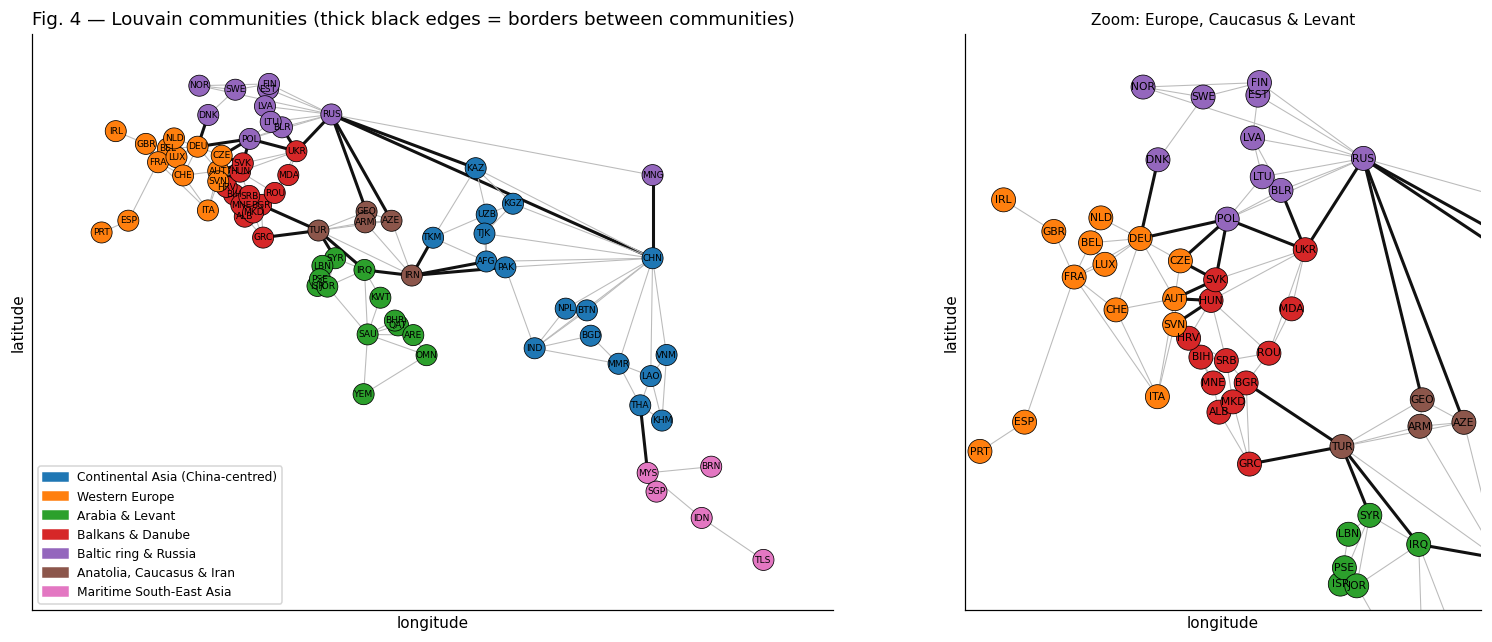

In [10]:
comm_list = prof.index.tolist()
comm_col = dict(zip(comm_list, plt.cm.tab10.colors[:len(comm_list)]))
leg = [mpl.patches.Patch(color=comm_col[c], label=c) for c in comm_list]
ec = {e: ("#bbbbbb" if comm_name[e[0]] == comm_name[e[1]] else "#111111") for e in G.edges()}
ew = {e: (0.7 if comm_name[e[0]] == comm_name[e[1]] else 2.0) for e in G.edges()}
draw_map({n: comm_col[comm_name[n]] for n in G},
         "Fig. 4 — Louvain communities (thick black edges = borders between communities)",
         legend=leg, edge_color=ec, edge_width=ew)

**Interpretation (RQ2).** With no information other than "who borders whom", Louvain recovers **seven geographically coherent blocs** with high modularity (Q ≈ 0.67; values above 0.3 are usually considered strong community structure):

| Community | What it is |
|---|---|
| **Western Europe** | The EU/EFTA core plus the British Isles and Iberia, held together by France and Germany |
| **Balkans & Danube** | Former Yugoslavia, Albania, Greece, Bulgaria, Romania, Hungary, Slovakia, plus Moldova and Ukraine |
| **Baltic ring & Russia** | Nordic and Baltic states, Poland, Belarus and Russia (with Mongolia attached through Russia) |
| **Anatolia, Caucasus & Iran** | Türkiye, Georgia, Armenia, Azerbaijan, Iran |
| **Arabia & Levant** | The Arabian Peninsula, Iraq, Jordan, Syria, Lebanon, Israel, Palestine |
| **Continental Asia** | China with Central, South and mainland South-East Asia |
| **Maritime South-East Asia** | Malaysia, Singapore, Brunei, Indonesia, Timor-Leste |

The partition is stable. The 100 Louvain runs agree with the chosen partition on average (mean ARI reported above), and the independent greedy algorithm finds a very similar structure. Communities largely mirror the UN subregions, but not exactly: Poland groups with the Baltic ring rather than with "Eastern Europe", and Iran groups with the Caucasus rather than South Asia. **The network "sees" contiguity, not official labels.**

The table also shows the first sign of the main finding. **Western Europe** is almost perfectly homogeneous (HDI standard deviation 0.02). **Arabia & Levant** (HDI sd ≈ 0.15) and **Continental Asia** (sd ≈ 0.09) contain countries at very different development levels.

---
### 6. Clustering countries by their attributes (RQ3)

Now we ignore the network and group countries **only by the four HDI components**: life expectancy, expected schooling, mean schooling and log₁₀ GNI per capita. Income is log-transformed because its effect on well-being is roughly logarithmic, and the raw values span two orders of magnitude (Yemen $1,018 vs Norway $112,710). All features are z-standardised so that each one weighs equally.

The number of clusters *k* is chosen with the **elbow** (inertia) and the **silhouette** score. Ward hierarchical clustering serves as a cross-check.

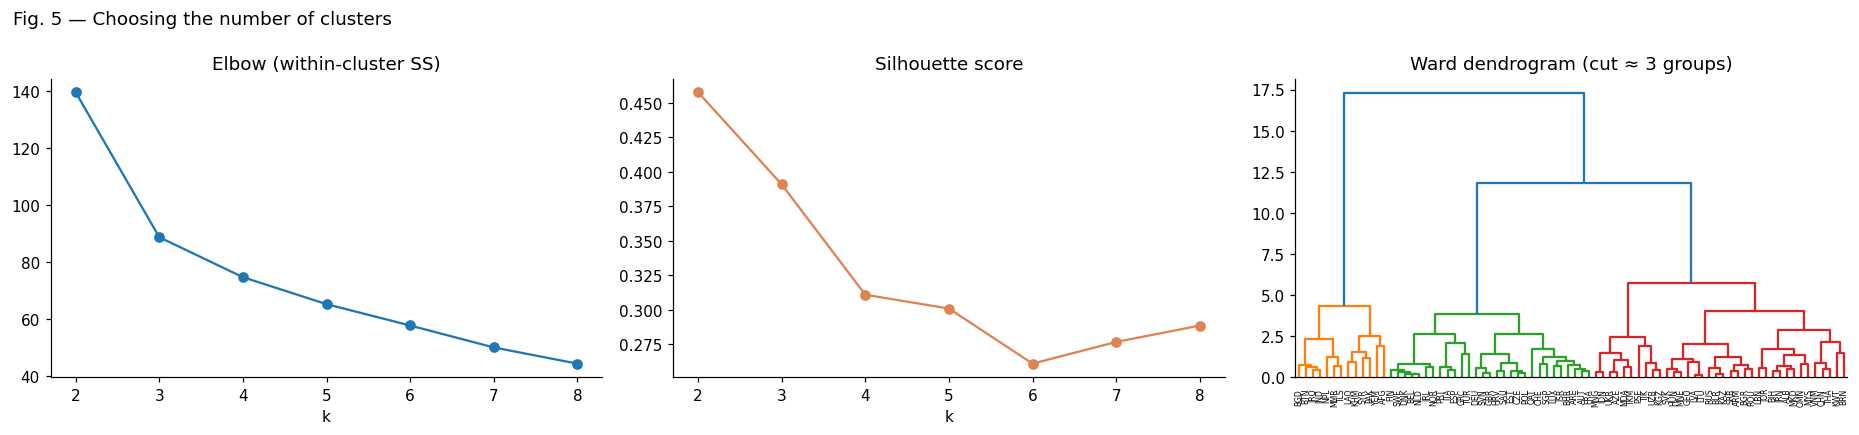

,inertia,silhouette
k,,
2,139.6,0.458
3,88.7,0.391
4,74.6,0.311
5,65.1,0.301
6,57.6,0.261
7,49.9,0.277
8,44.3,0.289


In [11]:
feat = ["life_expectancy", "expected_schooling", "mean_schooling", "log_gni"]
nodes["log_gni"] = np.log10(nodes.gni_pc_ppp)
scaler = StandardScaler().fit(nodes[feat]); Z = scaler.transform(nodes[feat])

ks = range(2, 9); inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=100, random_state=0).fit(Z)
    inertia.append(km.inertia_); sil.append(silhouette_score(Z, km.labels_))
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set(title="Elbow (within-cluster SS)", xlabel="k")
ax[1].plot(ks, sil, "o-", color="#dd8452"); ax[1].set(title="Silhouette score", xlabel="k")
dendrogram(linkage(Z, "ward"), labels=nodes.iso3.values, ax=ax[2], leaf_font_size=5, color_threshold=7.5)
ax[2].set_title("Ward dendrogram (cut ≈ 3 groups)")
fig.suptitle("Fig. 5 — Choosing the number of clusters", x=0.01, ha="left"); plt.tight_layout(); plt.show()
display(pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 3)}).set_index("k"))

The silhouette is highest at k = 2, but two groups only split "rich" from "everyone else", which is too coarse to be informative. The elbow bends at **k = 3**, the silhouette there is still good (≈ 0.39), and the Ward dendrogram also separates three main branches. We therefore use **k = 3**.

In [12]:
km = KMeans(n_clusters=3, n_init=100, random_state=0).fit(Z)
cent_df = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=feat)
cent_df["gni_pc_ppp"] = 10 ** cent_df.log_gni
order = cent_df.gni_pc_ppp.sort_values(ascending=False).index          # name clusters by income rank
cl_names = dict(zip(order, ["A · Advanced", "B · Upper-middle / transition", "C · Developing"]))
nodes["cluster"] = [cl_names[l] for l in km.labels_]
nx.set_node_attributes(G, dict(zip(nodes.iso3, nodes.cluster)), "cluster")

centroids = cent_df.rename(index=cl_names).drop(columns="log_gni").loc[list(cl_names.values())]
centroids["HDI (members' mean)"] = nodes.groupby("cluster").hdi.mean()
centroids["n countries"] = nodes.cluster.value_counts()
display(centroids.round(2))
ward = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(Z)
print(f"Agreement K-means vs Ward (ARI) = {adjusted_rand_score(km.labels_, ward):.2f}")
for c in cl_names.values():
    print(f"\n{c}:", ", ".join(sorted(nodes.country[nodes.cluster == c])))

,life_expectancy,expected_schooling,mean_schooling,gni_pc_ppp,HDI (members' mean),n countries
A · Advanced,81.22,17.10,12.24,56639.97,0.92,33
B · Upper-middle / transition,75.21,13.93,10.99,19867.22,0.80,31
C · Developing,69.78,11.21,5.93,5427.85,0.61,14


Agreement K-means vs Ward (ARI) = 0.79

A · Advanced: Austria, Bahrain, Belgium, Croatia, Czechia, Denmark, Estonia, Finland, France, Germany, Greece, Ireland, Israel, Italy, Kuwait, Latvia, Lithuania, Luxembourg, Netherlands, Norway, Poland, Portugal, Qatar, Saudi Arabia, Singapore, Slovakia, Slovenia, Spain, Sweden, Switzerland, Türkiye, United Arab Emirates, United Kingdom

B · Upper-middle / transition: Albania, Armenia, Azerbaijan, Belarus, Bosnia and Herzegovina, Brunei, Bulgaria, China, Georgia, Hungary, Indonesia, Iran, Jordan, Kazakhstan, Kyrgyzstan, Lebanon, Malaysia, Moldova, Mongolia, Montenegro, North Macedonia, Oman, Romania, Russia, Serbia, Tajikistan, Thailand, Turkmenistan, Ukraine, Uzbekistan, Viet Nam

C · Developing: Afghanistan, Bangladesh, Bhutan, Cambodia, India, Iraq, Laos, Myanmar, Nepal, Pakistan, Palestine, Syria, Timor-Leste, Yemen


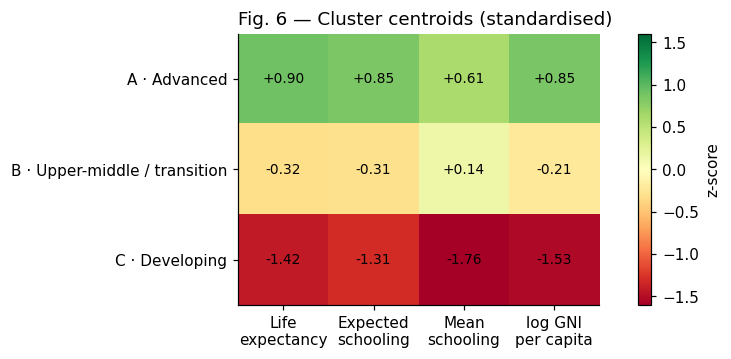

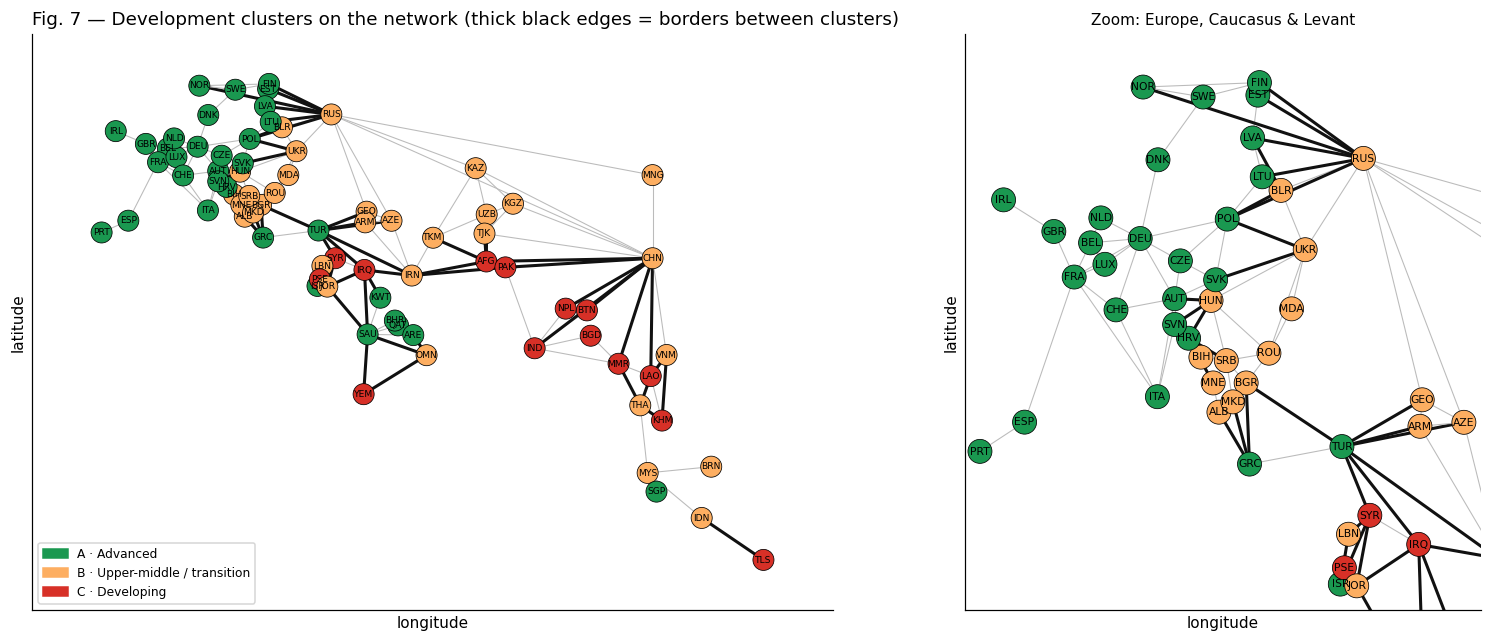

In [13]:
cl_col = {"A · Advanced": "#1a9850", "B · Upper-middle / transition": "#fdae61", "C · Developing": "#d73027"}
z = pd.DataFrame(km.cluster_centers_, columns=feat).rename(index=cl_names).loc[list(cl_col)]
fig, ax = plt.subplots(figsize=(9, 3.2))
im = ax.imshow(z.values, cmap="RdYlGn", vmin=-1.6, vmax=1.6)
ax.set_xticks(range(4)); ax.set_xticklabels(["Life\nexpectancy", "Expected\nschooling", "Mean\nschooling", "log GNI\nper capita"])
ax.set_yticks(range(3)); ax.set_yticklabels(z.index)
for i in range(3):
    for j in range(4): ax.text(j, i, f"{z.values[i, j]:+.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, label="z-score"); ax.set_title("Fig. 6 — Cluster centroids (standardised)", loc="left"); plt.show()

ec = {e: ("#bbbbbb" if G.nodes[e[0]]["cluster"] == G.nodes[e[1]]["cluster"] else "#111111") for e in G.edges()}
ew = {e: (0.7 if G.nodes[e[0]]["cluster"] == G.nodes[e[1]]["cluster"] else 2.0) for e in G.edges()}
draw_map({n: cl_col[G.nodes[n]["cluster"]] for n in G},
         "Fig. 7 — Development clusters on the network (thick black edges = borders between clusters)",
         legend=[mpl.patches.Patch(color=v, label=k) for k, v in cl_col.items()], edge_color=ec, edge_width=ew)

**Interpretation (RQ3).** The centroids, i.e. the prototypical members of each group, describe three clear development tiers:

* **A · Advanced (33 countries)** — life expectancy ≈ 81 years, ≈ 17 expected years of schooling, ≈ 12 mean years, GNI ≈ $57k. Western and Northern Europe, most of Central Europe and the Baltics, plus **Israel, Türkiye, Singapore and the Gulf monarchies** (Saudi Arabia, UAE, Qatar, Kuwait, Bahrain).
* **B · Upper-middle / transition (31 countries)** — ≈ 75 years, ≈ 14 / 11 years of schooling, GNI ≈ $20k. The Balkans, the post-Soviet space (Russia, Ukraine, Belarus, Caucasus, Central Asia), Iran, China, Mongolia, Thailand, Viet Nam, Malaysia, Indonesia, plus Jordan, Lebanon and Oman.
* **C · Developing (14 countries)** — ≈ 70 years, ≈ 11 years expected but only **≈ 6 mean years** of schooling, GNI ≈ $5k. South Asia, the poorer parts of mainland South-East Asia, and conflict-affected countries (Afghanistan, Syria, Yemen, Iraq, Palestine).

Fig. 6 shows *where* the tiers differ. The Developing tier is set apart above all by **mean years of schooling** (z ≈ −1.8) and income: its adults have, on average, only half the schooling of the other tiers. The step from Transition to Advanced is driven mainly by **life expectancy** and **income**, while adult schooling is already similar in the two upper tiers (≈ 11 vs 12 years). This matches the post-socialist profile of many tier-B countries: well-educated populations with lower incomes and shorter lives. K-means and Ward hierarchical clustering largely agree (ARI printed above), so the grouping is natural rather than an artefact of the algorithm.

---
### 7. Linking the two layers: does development follow the network? (RQ4)

We have two independent groupings of the same 78 countries: **communities** (from borders only) and **clusters** (from attributes only). Three complementary tests compare them:

1. **Overlap** of the two partitions (contingency table, ARI, NMI).
2. **Assortativity.** Are the attribute values of the two ends of each border correlated? Significance comes from a **permutation test** that shuffles attributes randomly over the fixed network 2,000 times.
3. **Development cliffs.** Which individual borders separate the most different countries?

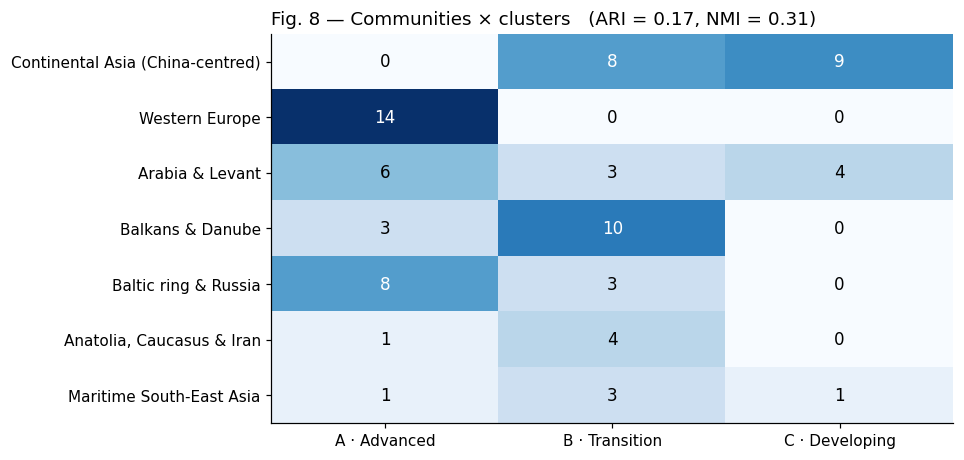

For reference: ARI(communities, UN subregions) = 0.45


In [14]:
ct = pd.crosstab(nodes.community, nodes.cluster).loc[comm_list, list(cl_col)]
ari = adjusted_rand_score(nodes.community, nodes.cluster); nmi = normalized_mutual_info_score(nodes.community, nodes.cluster)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.imshow(ct.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(["A · Advanced", "B · Transition", "C · Developing"]); ax.set_yticks(range(len(ct))); ax.set_yticklabels(ct.index)
for i in range(ct.shape[0]):
    for j in range(3): ax.text(j, i, ct.values[i, j], ha="center", va="center", fontsize=11,
                             color="white" if ct.values[i, j] >= 8 else "black")
ax.set_title(f"Fig. 8 — Communities × clusters   (ARI = {ari:.2f}, NMI = {nmi:.2f})", loc="left"); plt.show()
print(f"For reference: ARI(communities, UN subregions) = {adjusted_rand_score(nodes.community, nodes.subregion):.2f}")

,assortativity r,null mean,null 95th pct,p (perm.)
attribute,,,,
hdi,0.511,-0.016,0.115,< 0.0005
life_expectancy,0.478,-0.015,0.114,< 0.0005
expected_schooling,0.308,-0.017,0.110,< 0.0005
mean_schooling,0.540,-0.015,0.118,< 0.0005
log_gni,0.505,-0.017,0.115,< 0.0005
cluster (categorical),0.364,NaN,NaN,


Borders joining countries of the SAME development cluster: 61% (expected by chance ≈ 37%)


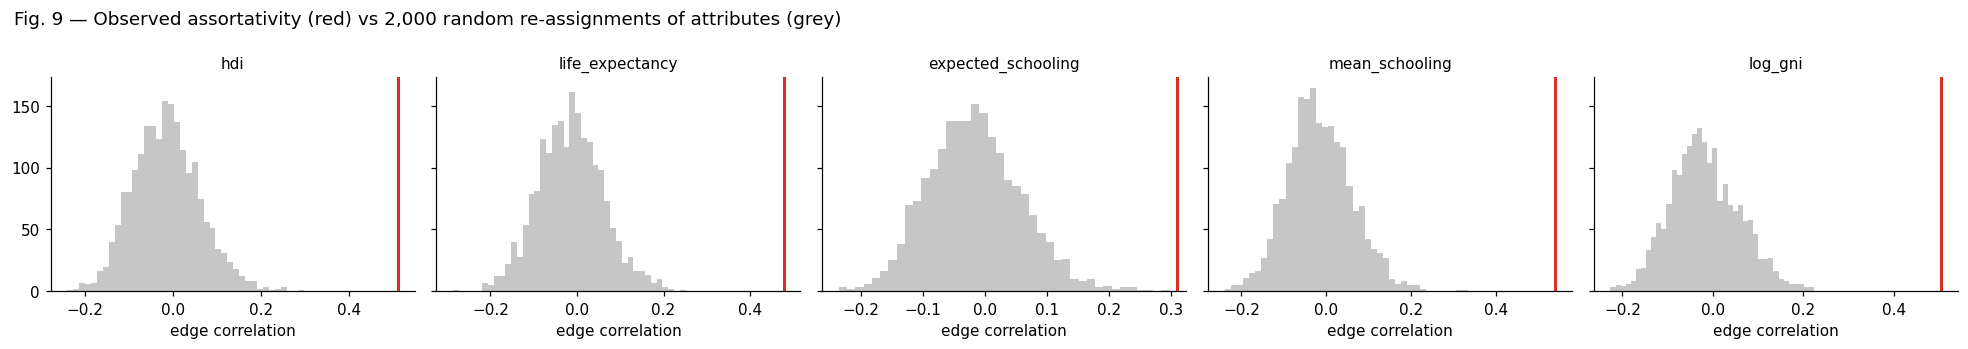

In [15]:
rng = np.random.default_rng(42)
iso = list(G.nodes()); E = np.array([(iso.index(a), iso.index(b)) for a, b in G.edges()])

def edge_corr(v):                       # Pearson correlation over both orientations of every edge
    x = np.r_[v[E[:, 0]], v[E[:, 1]]]; y = np.r_[v[E[:, 1]], v[E[:, 0]]]
    return np.corrcoef(x, y)[0, 1]

nodes_i = nodes.set_index("iso3").loc[iso]
res, nulls = [], {}
for a in ["hdi", "life_expectancy", "expected_schooling", "mean_schooling", "log_gni"]:
    v = nodes_i[a].values; obs = edge_corr(v)
    null = np.array([edge_corr(rng.permutation(v)) for _ in range(2000)]); nulls[a] = (obs, null)
    res.append({"attribute": a, "assortativity r": round(obs, 3), "null mean": round(null.mean(), 3),
                "null 95th pct": round(np.percentile(null, 95), 3), "p (perm.)": f"< {1/2000:.4f}" if (null >= obs).sum() == 0 else round((null >= obs).mean(), 4)})
res.append({"attribute": "cluster (categorical)", "assortativity r": round(nx.attribute_assortativity_coefficient(G, "cluster"), 3),
            "null mean": np.nan, "null 95th pct": np.nan, "p (perm.)": ""})
display(pd.DataFrame(res).set_index("attribute"))

same = np.mean([G.nodes[a]["cluster"] == G.nodes[b]["cluster"] for a, b in G.edges()])
p = nodes.cluster.value_counts(normalize=True); expct = (p ** 2).sum()
print(f"Borders joining countries of the SAME development cluster: {same:.0%} (expected by chance ≈ {expct:.0%})")

fig, axes = plt.subplots(1, 5, figsize=(18, 3.2), sharey=True)
for ax, (a, (obs, null)) in zip(axes, nulls.items()):
    ax.hist(null, bins=40, color="#c6c6c6"); ax.axvline(obs, color="#d73027", lw=2)
    ax.set_title(a, fontsize=10); ax.set_xlabel("edge correlation")
fig.suptitle("Fig. 9 — Observed assortativity (red) vs 2,000 random re-assignments of attributes (grey)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

Mean within-community HDI s.d.: observed 0.074 vs random 0.116  (p = 0.0000)


,border,HDI gap,GNI ratio (rich/poor),same community?
0,Saudi Arabia – Yemen,0.43,49.41,True
1,Oman – Yemen,0.39,35.46,True
2,Syria – Israel,0.36,12.26,True
3,Iran – Afghanistan,0.30,8.16,False
4,Afghanistan – China,0.30,11.17,True
5,Türkiye – Syria,0.29,8.81,False
6,Turkmenistan – Afghanistan,0.27,8.98,True
7,Iran – Pakistan,0.26,2.93,False
8,Pakistan – China,0.25,4.00,True
9,Israel – Palestine,0.24,7.34,True


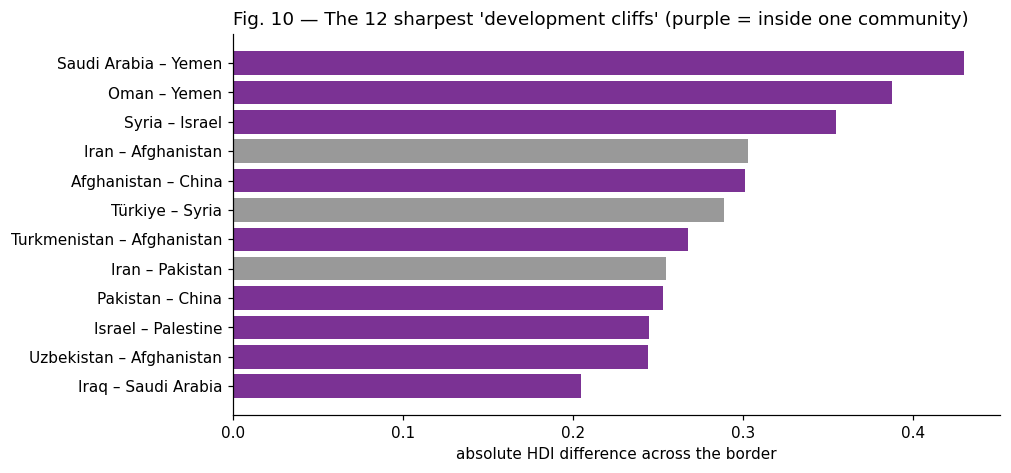

In [16]:
# Within-community homogeneity: are communities more homogeneous in HDI than random groups of the same sizes?
sizes = nodes.community.value_counts().values
def within_sd(lbl): return pd.Series(nodes.hdi.values).groupby(lbl).std().mean()
obs_sd = within_sd(nodes.community.values)
null_sd = [within_sd(rng.permutation(nodes.community.values)) for _ in range(2000)]
print(f"Mean within-community HDI s.d.: observed {obs_sd:.3f} vs random {np.mean(null_sd):.3f}  "
      f"(p = {np.mean(np.array(null_sd) <= obs_sd):.4f})")

# Development cliffs: borders with the largest HDI gap
cl = pd.DataFrame([{"border": f"{name[a]} – {name[b]}", "HDI gap": abs(G.nodes[a]["hdi"] - G.nodes[b]["hdi"]),
                    "GNI ratio (rich/poor)": max(G.nodes[a]["gni_pc_ppp"], G.nodes[b]["gni_pc_ppp"]) /
                                             min(G.nodes[a]["gni_pc_ppp"], G.nodes[b]["gni_pc_ppp"]),
                    "same community?": comm_name[a] == comm_name[b]} for a, b in G.edges()])
cl = cl.sort_values("HDI gap", ascending=False).reset_index(drop=True)
display(cl.head(12).round(2))
fig, ax = plt.subplots(figsize=(9, 4.5))
t = cl.head(12)[::-1]
ax.barh(t.border, t["HDI gap"], color=["#7b3294" if s else "#999999" for s in t["same community?"]])
ax.set_xlabel("absolute HDI difference across the border")
ax.set_title("Fig. 10 — The 12 sharpest 'development cliffs' (purple = inside one community)", loc="left"); plt.show()

In [17]:
# Which countries sit on the boundary between development tiers?
bnd = pd.DataFrame({
    "country": [name[n] for n in G], "cluster": [G.nodes[n]["cluster"] for n in G],
    "cross-cluster borders": [sum(G.nodes[m]["cluster"] != G.nodes[n]["cluster"] for m in G[n]) for n in G],
    "degree": [G.degree(n) for n in G], "betweenness": [round(cent.betweenness[n], 3) for n in G]})
bnd["share cross-cluster"] = (bnd["cross-cluster borders"] / bnd.degree).round(2)
display(bnd.sort_values(["cross-cluster borders", "betweenness"], ascending=False).head(10).set_index("country"))

,cluster,cross-cluster borders,degree,betweenness,share cross-cluster
country,,,,,
China,B · Upper-middle / transition,7,13,0.323,0.54
Türkiye,A · Advanced,7,8,0.224,0.88
Russia,B · Upper-middle / transition,6,13,0.463,0.46
Iraq,C · Developing,5,6,0.199,0.83
Afghanistan,C · Developing,5,6,0.050,0.83
Jordan,B · Upper-middle / transition,5,5,0.028,1.00
Iran,B · Upper-middle / transition,4,7,0.159,0.57
Saudi Arabia,A · Advanced,4,8,0.126,0.50
Hungary,B · Upper-middle / transition,4,7,0.094,0.57


**Interpretation (RQ4).**

* **Neighbours are strongly alike.** Every development indicator is positively assortative across borders: r ≈ 0.51 for HDI, 0.54 for mean schooling, 0.50 for log income and 0.48 for life expectancy. In 2,000 random re-assignments of attribute values over the same network, the correlation is never that high (null mean ≈ 0, p < 0.001). About **61 %** of borders connect two countries of the same development cluster, against ≈ 37 % expected by chance. Communities are also significantly more homogeneous in HDI than random groups of equal size. *Development does cross borders.*
* **But blocs are not development tiers.** The overlap between communities and clusters is modest (ARI ≈ 0.17, NMI ≈ 0.31); geography (UN subregions) is matched far better (ARI ≈ 0.45). Fig. 8 shows why. Only **Western Europe** is a pure "Advanced" bloc (14/14). The **Balkans & Danube** bloc is mostly "transition", and the **Baltic ring & Russia** bloc mixes advanced Nordics/Baltics/Poland with transition Russia, Belarus and Mongolia. **Arabia & Levant** contains *all three* tiers.
* **The rule breaks down at specific cliffs.** The sharpest borders are **Saudi Arabia–Yemen** and **Oman–Yemen**, then **Israel–Syria**, **Iran–Afghanistan**, **China–Afghanistan**, **Türkiye–Syria**, **Israel–Palestine** and **China–Pakistan**. Two kinds of cliff appear: (i) **resource-rich vs conflict-affected** neighbours in the Middle East, where oil wealth or war overrides geography, and (ii) **Afghanistan and Pakistan**, low-development outliers surrounded by transition economies. Most of the top cliffs lie *inside* a single border community (purple bars). These are places where countries are tightly connected geographically but sharply divided in living standards.
* **Bridges between tiers.** Russia, China, Türkiye, Iran and Iraq have the most cross-cluster borders and also high betweenness. The countries that hold the network together are the same ones that stand on the frontiers between development levels.

---
### 8. Exploratory mapping: MDS and t-SNE

Finally, we place the countries in a 2-D **attribute space** (the four standardised HDI components) with two dimensionality-reduction methods:

* **MDS** preserves global Euclidean distances (faithful to the overall layout of the data cloud).
* **t-SNE** preserves local neighbourhoods (good at revealing tight groups; distances between groups should not be over-interpreted).

On each map we overlay **(left) the K-means clusters** and **(right) the network communities**. If communities were defined by development, their colours would form compact islands on these maps.

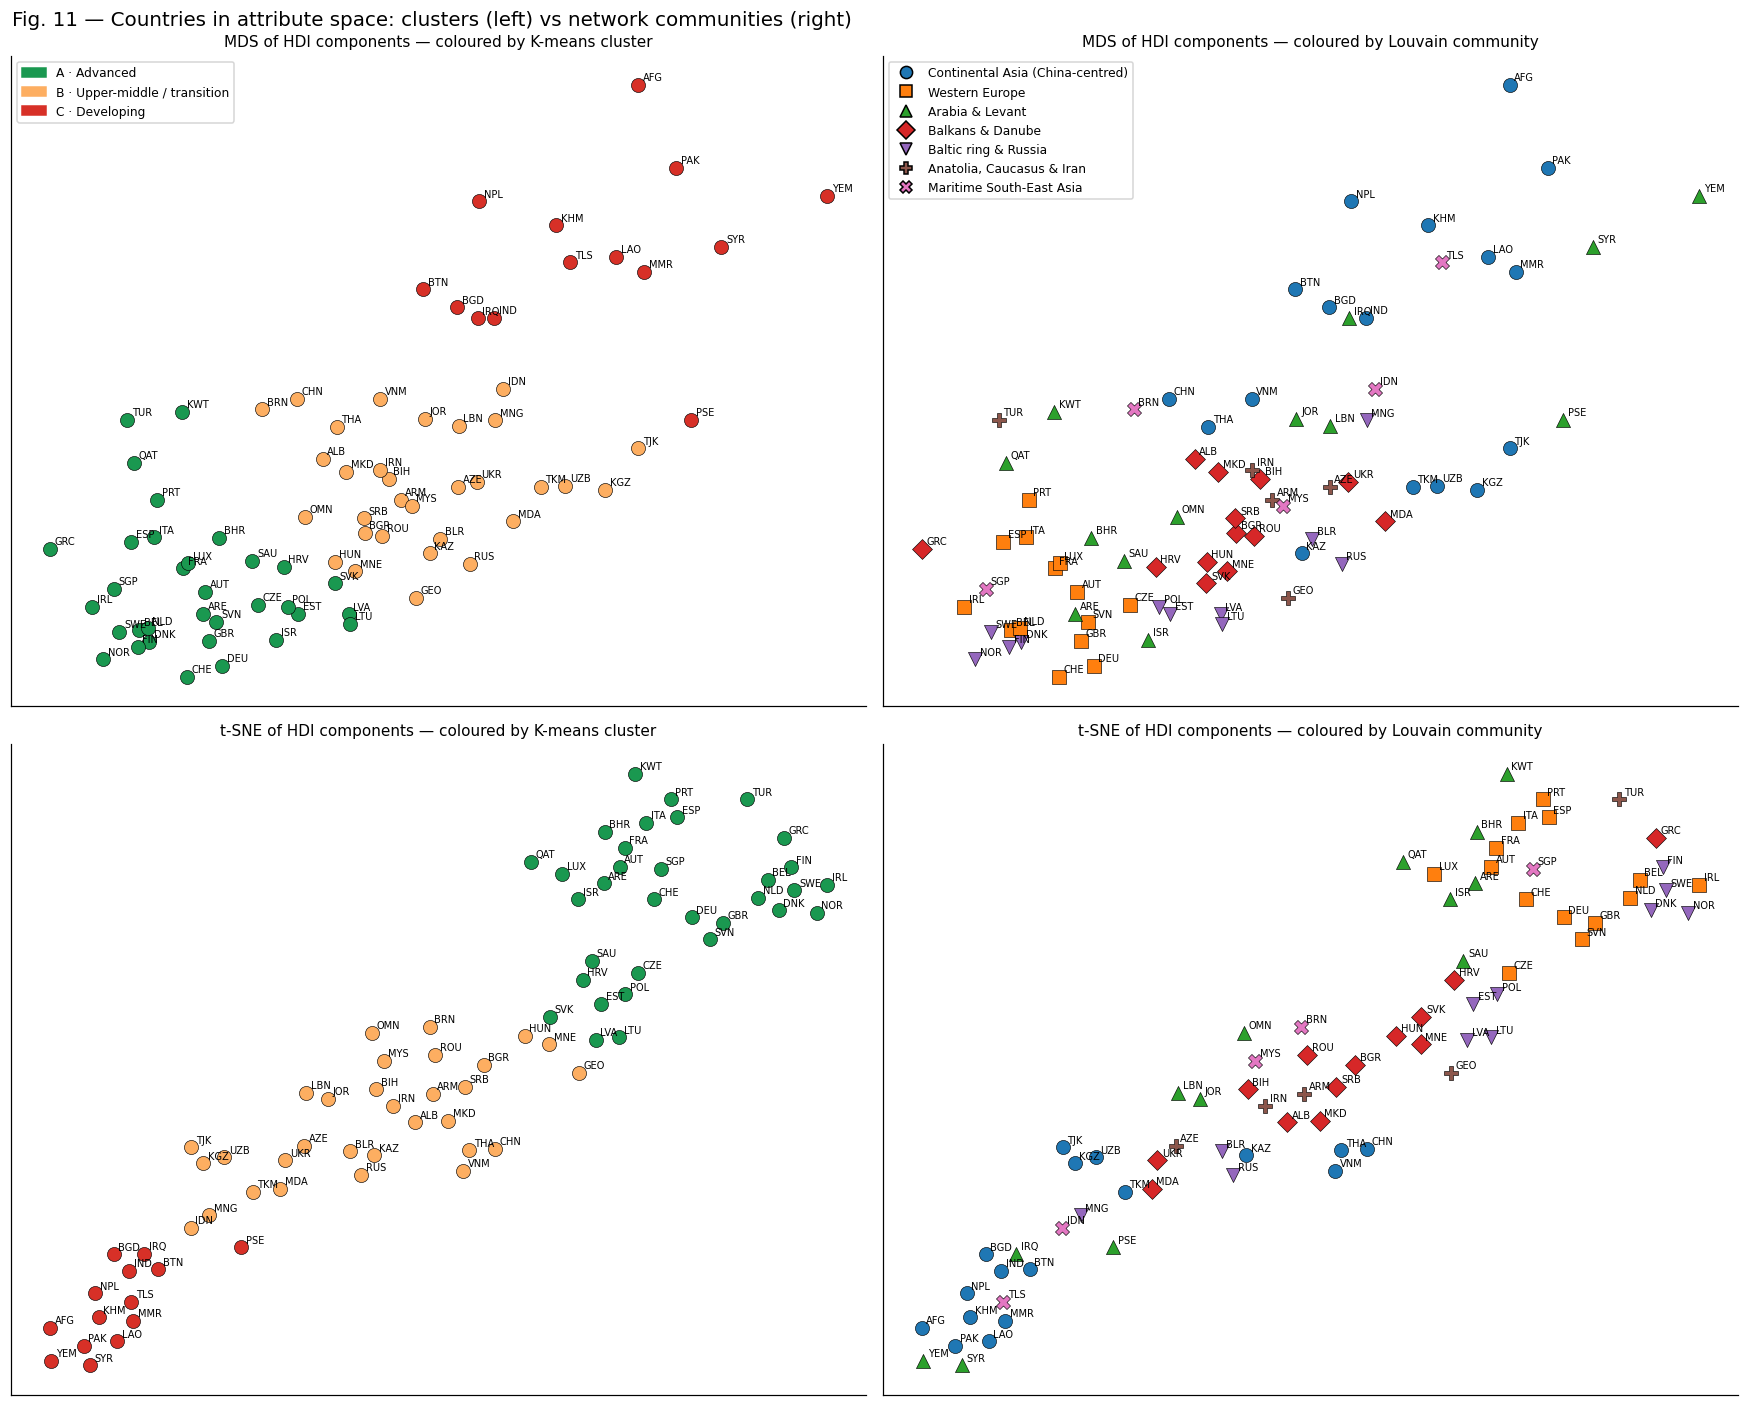

In [18]:
emb = {"MDS": MDS(n_components=2, random_state=1, n_init=8, normalized_stress="auto").fit_transform(Z),
       "t-SNE": TSNE(n_components=2, perplexity=12, random_state=1, init="pca").fit_transform(Z)}
markers = dict(zip(comm_list, ["o", "s", "^", "D", "v", "P", "X"]))
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for row, (meth, Y) in enumerate(emb.items()):
    for col, layer in enumerate(["cluster", "community"]):
        ax = axes[row, col]
        for i, r in nodes.iterrows():
            ax.scatter(Y[i, 0], Y[i, 1], s=85, edgecolor="black", linewidth=0.4,
                       c=[cl_col[r.cluster]] if layer == "cluster" else [comm_col[r.community]],
                       marker=markers[r.community] if layer == "community" else "o")
            ax.annotate(r.iso3, (Y[i, 0], Y[i, 1]), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
        ax.set_title(f"{meth} of HDI components — coloured by {'K-means cluster' if layer=='cluster' else 'Louvain community'}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].legend(handles=[mpl.patches.Patch(color=v, label=k) for k, v in cl_col.items()], fontsize=8, loc="best")
axes[0, 1].legend(handles=[mpl.lines.Line2D([], [], marker=markers[c], color="w", markerfacecolor=comm_col[c],
                  markeredgecolor="k", markersize=8, label=c) for c in comm_list], fontsize=8, loc="best")
fig.suptitle("Fig. 11 — Countries in attribute space: clusters (left) vs network communities (right)", x=0.01, ha="left", fontsize=13)
plt.tight_layout(); plt.show()

**Interpretation.** In both projections the K-means clusters form clean bands along a single dominant axis: development runs from Yemen, Afghanistan and Pakistan on one side to Norway and Switzerland on the other. This confirms that the three tiers are a real structure in the data.

The network communities behave differently. **Western Europe** forms one tight patch (homogeneous, rich), and **Balkans & Danube** occupies a fairly compact middle band, with Greece as the exception. Other blocs are spread out: in **Anatolia, Caucasus & Iran**, Türkiye sits with the advanced countries, apart from its Caucasian neighbours. **Arabia & Levant** is scattered across the whole map: the UAE and Qatar sit beside Western Europe, while Yemen and Syria sit at the far developing end. **Continental Asia** stretches from China and Kazakhstan (transition) to Afghanistan and Nepal (developing). The maps show visually what Fig. 8 showed numerically: *location predicts development well locally, but some border regions contain very different societies.*

---
### 9. Saving the enriched network

All layers are stored as node attributes (UNDP indicators, centrality, Louvain community, K-means cluster) and exported as GraphML, so the same network can be opened and restyled in **Cytoscape** or Gephi.

In [19]:
H = G.copy()
for n in H:
    for k, v in list(H.nodes[n].items()):
        if isinstance(v, (np.integer,)): H.nodes[n][k] = int(v)
        elif isinstance(v, (np.floating,)): H.nodes[n][k] = float(v)
nx.write_graphml(H, "eurasia_hdi_network.graphml")
out = nodes.merge(cent.drop(columns=["country", "hdi"]), left_on="iso3", right_index=True)
out.to_csv("nodes_with_results.csv", index=False)
print("Saved: eurasia_hdi_network.graphml, nodes_with_results.csv  —", out.shape)

Saved: eurasia_hdi_network.graphml, nodes_with_results.csv  — (78, 22)


### 10. Conclusions — did we answer the question?

**Yes. Development does cross borders, but not everywhere, and the exceptions are the most informative part of the result.**

1. **RQ1 – Centrality.** The Eurasian border network is held together by a few giant hinge states. **Russia** and **China** dominate degree, betweenness, closeness and eigenvector centrality; **Türkiye, Poland, Germany, Iraq and Iran** are the secondary bridges. Structural importance has **no relationship with development** (all |ρ| < 0.2, n.s.): the most developed countries are peripheral.
2. **RQ2 – Communities.** Louvain finds **7 stable, geographically coherent blocs** (Q ≈ 0.67) that resemble, but do not copy, the UN subregions.
3. **RQ3 – Clusters.** Attribute-only K-means gives **3 development tiers** (Advanced / Upper-middle–transition / Developing), confirmed by Ward clustering. The Developing tier is defined above all by low adult schooling; the Advanced tier differs from the Transition tier mainly in life expectancy and income.
4. **RQ4 – Linking layers.** Neighbouring countries are much more alike than chance in every indicator (assortativity ≈ 0.5, p < 0.001; ~61 % of borders stay within one tier vs ~37 % expected). Communities, however, coincide only partly with tiers (ARI ≈ 0.17). Western Europe is a homogeneous "club"; the **Middle East** and the **Afghanistan–Pakistan** area hold the sharpest **development cliffs** (Saudi Arabia/Oman–Yemen, Israel–Syria/Palestine, Iran/China–Afghanistan). There, resource wealth, conflict and political separation override geographic proximity.

**Answer in one sentence:** *Geographic neighbourhood is a strong but not sufficient predictor of human development; in Europe and East Asia prosperity is smoothly shared across borders, while the Middle East and the Afghan–Pakistani frontier show that wealth and conflict can create steep cliffs between countries that are geographically tightly connected.*

**Limitations.**

* A border is a proxy for interaction, not a measure of it. Weighted networks of actual trade or migration flows would show how strong each connection is.
* The analysis is a single 2023 cross-section, so it cannot separate cause from effect (do neighbours converge, or were they always similar?).
* The inclusion rules (fixed links, exclusion of islands and micro-states) affect the network, especially the British Isles and the Gulf.
* Louvain is stochastic; this is mitigated by 100 runs and a second algorithm.
* The UNDP figures for conflict-affected countries (Syria, Yemen, Afghanistan, Palestine) carry more uncertainty.

**Possible extensions:** weight edges by bilateral trade (e.g. UN Comtrade); repeat for 2000 and 2010 to see whether cliffs are closing; compute a formal spatial autocorrelation statistic (Moran's I) on the same adjacency matrix.

### References
* UNDP (2025). *Human Development Report 2025*, Statistical Annex, Table 1 "Human Development Index and its components". hdr.undp.org
* United Nations Statistics Division. *Standard country or area codes for statistical use (M49)*.
* Blondel, V. D., Guillaume, J.-L., Lambiotte, R., Lefebvre, E. (2008). Fast unfolding of communities in large networks. *J. Stat. Mech.* P10008.
* Newman, M. E. J. (2003). Mixing patterns in networks. *Physical Review E* 67, 026126.
* Hagberg, A., Schult, D., Swart, P. (2008). Exploring network structure, dynamics, and function using NetworkX. *SciPy 2008*.
* Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR* 12.